# Grover's Search Algorithm

Grover's algorithm searches an unsorted list of N = 2<sup>n</sup> items for one **marked** item.
A classical search needs about N/2 tries on average; Grover needs only about
**(π/4)·√N** calls to the oracle, a quadratic speed-up.

Steps:
1. **Superposition:** H on all n qubits gives an equal superposition of all N states.
2. **Oracle:** flips the sign (phase) of the marked state only:
   X on qubits where the marked bit is 0 → multi-controlled Z → undo the X gates.
3. **Diffuser:** reflects every amplitude about the average (H, X, multi-controlled Z, X, H),
   which makes the marked state's amplitude grow.
4. Repeat oracle + diffuser **k = ⌊(π/4)·√N⌋** times, then measure.

**Input:** the marked state as an n-bit string (n ≥ 2, e.g. `101`).
**Expected:** the most frequent result is the marked state (`Correct: True`), with high probability.
The second cell saves the circuit diagram as a PNG.

Enter the marked state to search for (e.g. 101): 101


Number of qubits n = 3
Search space N = 8
Grover iterations = 2

Counts: {'101': 959, '111': 15, '000': 11, '001': 10, '010': 10, '100': 7, '110': 7, '011': 5}
Marked state: 101
Found state : 101
Probability of marked state: 0.9365234375
Correct: True


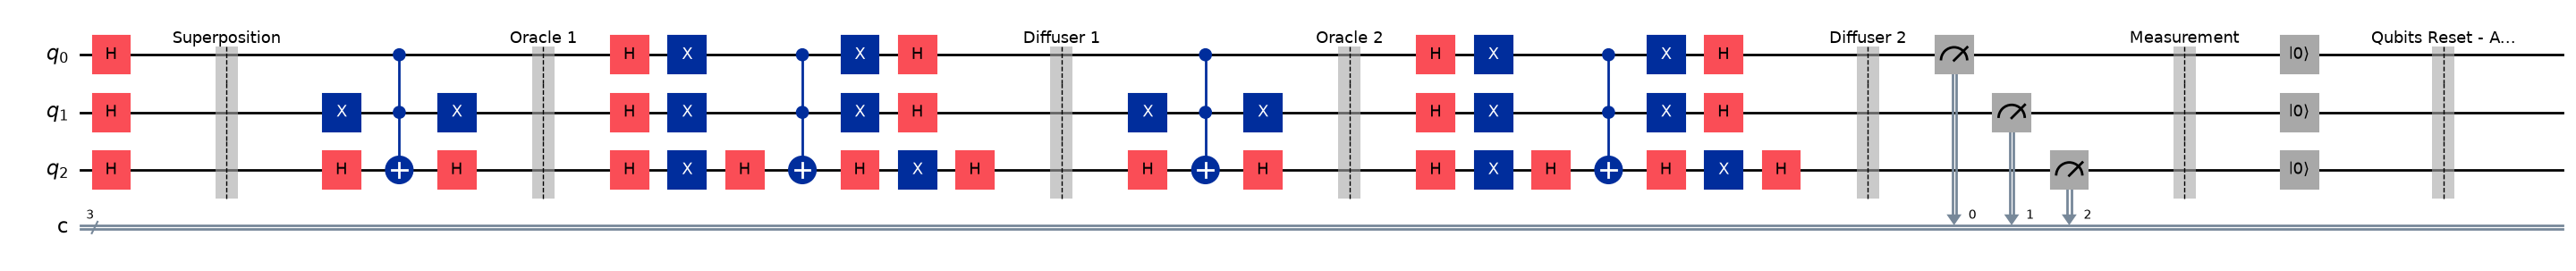

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
import numpy as np

# Input marked state
marked = input("Enter the marked state to search for (e.g. 101): ").strip()

if len(marked) < 2 or set(marked) - {"0", "1"}:
    raise ValueError("Enter a string of 0s and 1s with at least 2 bits.")

n = len(marked)
N = 2 ** n
iterations = int(np.floor(np.pi / 4 * np.sqrt(N)))

print("Number of qubits n =", n)
print("Search space N =", N)
print("Grover iterations =", iterations)

# Registers
q = QuantumRegister(n, 'q')
c = ClassicalRegister(n, 'c')

qc = QuantumCircuit(q, c)


# Multi-controlled Z on all qubits (H + multi-controlled X + H on the last qubit)
def mcz(qc):
    qc.h(q[n - 1])
    qc.mcx(list(q[:n - 1]), q[n - 1])
    qc.h(q[n - 1])


# Superposition
for i in range(n):
    qc.h(q[i])
qc.barrier(label="Superposition")

for k in range(iterations):
    # Oracle: flip the phase of the marked state
    # marked is written q[n-1]...q[0], like Qiskit results
    for i in range(n):
        if marked[n - 1 - i] == "0":
            qc.x(q[i])
    mcz(qc)
    for i in range(n):
        if marked[n - 1 - i] == "0":
            qc.x(q[i])
    qc.barrier(label=f"Oracle {k + 1}")

    # Diffuser: reflect about the average amplitude
    for i in range(n):
        qc.h(q[i])
        qc.x(q[i])
    mcz(qc)
    for i in range(n):
        qc.x(q[i])
        qc.h(q[i])
    qc.barrier(label=f"Diffuser {k + 1}")

# Measurement
for i in range(n):
    qc.measure(q[i], c[i])
qc.barrier(label="Measurement")

# Reset all qubits after measurement
for i in range(n):
    qc.reset(q[i])
qc.barrier(label="Qubits Reset - Available for Reuse")

# Run circuit
shots = 1024
result = AerSimulator().run(qc, shots=shots).result()
counts = result.get_counts()
print("\nCounts:", dict(sorted(counts.items(), key=lambda kv: -kv[1])))

found = max(counts, key=counts.get)

print("Marked state:", marked)
print("Found state :", found)
print("Probability of marked state:", counts.get(marked, 0) / shots)
print("Correct:", found == marked)

# Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("6_Grover.png", dpi=300, bbox_inches="tight")